# Laboratório 02 — HPA: escalonamento horizontal por CPU

Continuação do laboratório de liveness/readiness. **Simulação matemática local**, sem Kubernetes, metrics-server ou cluster ativo. Os números de carga são cenários artificiais, não medições da AWS/EKS.


## Entendendo o modelo

No Kubernetes, o HPA utiliza, em sua forma básica, `ceil(replicas_atuais * metrica_atual / metrica_alvo)`. Aqui aproximamos `métrica_atual` como consumo total de CPU dividido igualmente entre réplicas, com requests de 100m por pod. Target: 60%; tolerância didática: 10%; min=2, max=8.

**Simplificações:** não simulamos pods NotReady, métricas ausentes, readiness delay, políticas de velocidade, janela de estabilização, latência de provisionamento nem o loop real do controlador. Em Kubernetes, scale-down costuma ser estabilizado; portanto **o traçado não representa cronograma real de redução**.


In [1]:
import sys, math, csv
from pathlib import Path
print("Python:",sys.version.split()[0])


Python: 3.12.15


In [2]:
carga_total_mcpu = [65, 80, 180, 310, 400, 400, 330, 160, 100, 75, 60, 55]
replicas, request_mcpu, alvo_pct = 2, 100, 60
min_replicas, max_replicas, tolerancia = 2, 8, 0.10
resultados = []
for passo, carga in enumerate(carga_total_mcpu, start=1):
    cpu_media_pct = 100 * carga / (request_mcpu * replicas)
    razao = cpu_media_pct / alvo_pct
    recomendadas = replicas if abs(razao - 1) <= tolerancia else max(min_replicas, min(max_replicas, math.ceil(replicas * razao)))
    resultados.append({"passo":passo,"carga_total_mCPU":carga,"replicas_antes":replicas,"cpu_media_pct":round(cpu_media_pct,1),"replicas_recomendadas":recomendadas})
    replicas = recomendadas
for linha in resultados: print(linha)


{'passo': 1, 'carga_total_mCPU': 65, 'replicas_antes': 2, 'cpu_media_pct': 32.5, 'replicas_recomendadas': 2}
{'passo': 2, 'carga_total_mCPU': 80, 'replicas_antes': 2, 'cpu_media_pct': 40.0, 'replicas_recomendadas': 2}
{'passo': 3, 'carga_total_mCPU': 180, 'replicas_antes': 2, 'cpu_media_pct': 90.0, 'replicas_recomendadas': 3}
{'passo': 4, 'carga_total_mCPU': 310, 'replicas_antes': 3, 'cpu_media_pct': 103.3, 'replicas_recomendadas': 6}
{'passo': 5, 'carga_total_mCPU': 400, 'replicas_antes': 6, 'cpu_media_pct': 66.7, 'replicas_recomendadas': 7}
{'passo': 6, 'carga_total_mCPU': 400, 'replicas_antes': 7, 'cpu_media_pct': 57.1, 'replicas_recomendadas': 7}
{'passo': 7, 'carga_total_mCPU': 330, 'replicas_antes': 7, 'cpu_media_pct': 47.1, 'replicas_recomendadas': 6}
{'passo': 8, 'carga_total_mCPU': 160, 'replicas_antes': 6, 'cpu_media_pct': 26.7, 'replicas_recomendadas': 3}
{'passo': 9, 'carga_total_mCPU': 100, 'replicas_antes': 3, 'cpu_media_pct': 33.3, 'replicas_recomendadas': 2}
{'passo': 1

In [3]:
assert len(resultados)==12
assert resultados[0]["replicas_recomendadas"]==2
assert max(r["replicas_recomendadas"] for r in resultados)<=8
assert any(r["replicas_recomendadas"]>r["replicas_antes"] for r in resultados)
assert any(r["replicas_recomendadas"]<r["replicas_antes"] for r in resultados)
print("Testes do modelo didático: OK")


Testes do modelo didático: OK


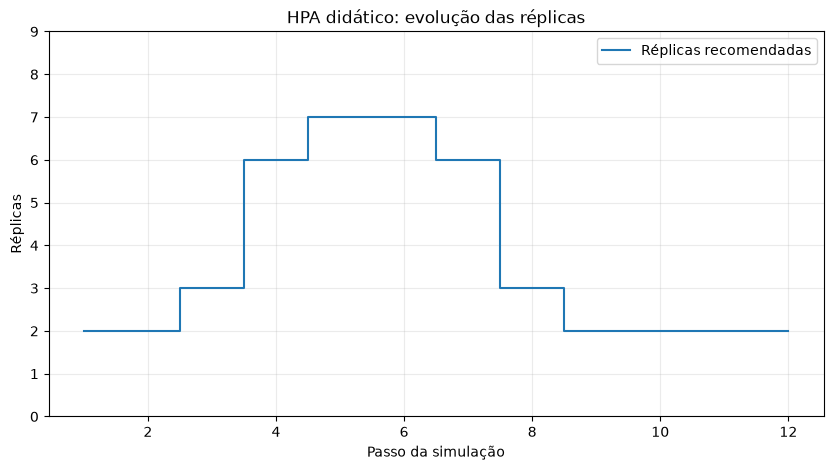

In [4]:
import matplotlib.pyplot as plt
x=[r["passo"] for r in resultados]
y=[r["replicas_recomendadas"] for r in resultados]
plt.figure(figsize=(10,5))
plt.step(x,y,where="mid",label="Réplicas recomendadas")
plt.xlabel("Passo da simulação");plt.ylabel("Réplicas");plt.title("HPA didático: evolução das réplicas");plt.ylim(0,9);plt.grid(alpha=.25);plt.legend();plt.show()


In [5]:
pasta=Path("artifacts/hpa");pasta.mkdir(parents=True,exist_ok=True)
with (pasta/"simulacao_hpa.csv").open("w",newline="") as f:
    w=csv.DictWriter(f,fieldnames=resultados[0].keys());w.writeheader();w.writerows(resultados)
print("Arquivo gerado:",pasta/"simulacao_hpa.csv")


Arquivo gerado: artifacts/hpa/simulacao_hpa.csv


## Para avançar ao Kubernetes real

Usar Deployment com CPU `requests`, metrics-server operacional e HPA `autoscaling/v2`, verificar `kubectl get hpa -w`, `kubectl top pods`, readiness e eventos. **Não declarar execução real a partir desta simulação.**

Referências: [Horizontal Pod Autoscaling](https://kubernetes.io/docs/concepts/workloads/autoscaling/horizontal-pod-autoscale/) e [API HPA v2](https://kubernetes.io/docs/reference/kubernetes-api/autoscaling/horizontal-pod-autoscaler-v2/).